In [37]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
from copy import deepcopy
import plotnine as p9

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
PROJECT_DIR = Path().resolve()
OUTPUT_DIR = PROJECT_DIR / "output"

SELECTED_TEST_RUN_TYPE = "lossless"
SELECTED_TEST_RUN_ID = "full-2026-07-26T20:33:06+02:00"
DATASET_NAME = "Canislupus_CZM_712"

RUN_DIR = OUTPUT_DIR / SELECTED_TEST_RUN_TYPE / SELECTED_TEST_RUN_ID / DATASET_NAME
assert RUN_DIR.exists(), f"Run directory {RUN_DIR} does not exist"

In [20]:
# Load data
datas = []
for file in RUN_DIR.glob("*.json"):
    with file.open("r") as f:
        test_data = json.load(f)
    datas.append(test_data)
    print(f"Loaded test data from {file.name}:")

Loaded test data from test_{"name":null,"is_lossless":true,"chunks":[3,2000,2000],"filters":null,"serializer":["Jpegxl",{"level":5,"effort":3,"lossless":true}],"compressors":null}.json:
Loaded test data from test_{"name":null,"is_lossless":true,"chunks":[3,2000,2000],"filters":null,"serializer":["Jpegxl",{"level":5,"effort":6,"lossless":true}],"compressors":null}.json:
Loaded test data from test_{"name":null,"is_lossless":true,"chunks":[3,2000,2000],"filters":null,"serializer":["Jpegxl",{"level":5,"effort":2,"lossless":true}],"compressors":null}.json:
Loaded test data from test_{"name":"no-op","is_lossless":true,"chunks":[3,2000,2000],"filters":null,"serializer":["BytesCodec",{}],"compressors":null}.json:
Loaded test data from test_{"name":null,"is_lossless":true,"chunks":[1,1000,1000],"filters":null,"serializer":["Jpegxl",{"level":5,"effort":3,"lossless":true}],"compressors":null}.json:
Loaded test data from test_{"name":null,"is_lossless":true,"chunks":[3,2000,2000],"filters":null,"s

In [21]:
datas[0]

{'name': '{"name":null,"is_lossless":true,"chunks":[3,2000,2000],"filters":null,"serializer":["Jpegxl",{"level":5,"effort":3,"lossless":true}],"compressors":null}',
 'id': '{"name":null,"is_lossless":true,"chunks":[3,2000,2000],"filters":null,"serializer":["Jpegxl",{"level":5,"effort":3,"lossless":true}],"compressors":null}',
 'dataset_name': 'Canislupus_CZM_712',
 'dataset_path': '/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712',
 'start_dt': '2026-07-26T18:40:56.333393Z',
 'end_dt': '2026-07-26T18:41:39.854242Z',
 'total_time_seconds': 43.520849,
 'config': {'name': None,
  'is_lossless': True,
  'chunks': [3, 2000, 2000],
  'filters': None,
  'serializer': ['Jpegxl', {'level': 5, 'effort': 3, 'lossless': True}],
  'compressors': None},
 'baseline_test': {'name': 'baseline',
  'id': '{"name":"baseline","is_lossless":true,"chunks":[3,2000,2000],"filters":null,"serializer":["Jpegxl",{"level":5,"effort":3,"lossless":true}],"compressors":n

In [23]:
from collections.abc import Mapping, Sequence


def flatten(data, prefix: str = "", sep: str = "__") -> dict:
    flattened = {}

    if isinstance(data, Mapping):
        for key, value in data.items():
            column = f"{prefix}{sep}{key}" if prefix else str(key)
            flattened.update(flatten(value, column, sep))

    elif isinstance(data, Sequence) and not isinstance(data, (str, bytes)):
        for index, value in enumerate(data):
            column = f"{prefix}[{index}]"
            flattened.update(flatten(value, column, sep))

    else:
        flattened[prefix] = data

    return flattened


rows = []
for data in datas:
    row = deepcopy(data)

    # Clean up a bit to reduce noise
    row.pop("array_info")
    row["baseline_test"].pop("array_info")

    rows.append({**row, **flatten(row)})

df = pl.DataFrame(rows, strict=False)
df


name,id,dataset_name,dataset_path,start_dt,end_dt,total_time_seconds,config,baseline_test,compress_time_seconds,nbytes,nbytes_stored,bitrate,bitrate_compressed,compression_ratio,lossless,config__name,config__is_lossless,config__chunks[0],config__chunks[1],config__chunks[2],config__filters,config__serializer[0],config__serializer[1]__level,config__serializer[1]__effort,config__serializer[1]__lossless,config__compressors,baseline_test__name,baseline_test__id,baseline_test__dataset_name,baseline_test__dataset_path,baseline_test__start_dt,baseline_test__end_dt,baseline_test__total_time_seconds,baseline_test__config__name,baseline_test__config__is_lossless,baseline_test__config__chunks[0],baseline_test__config__chunks[1],baseline_test__config__chunks[2],baseline_test__config__filters,baseline_test__config__serializer[0],baseline_test__config__serializer[1]__level,baseline_test__config__serializer[1]__effort,baseline_test__config__serializer[1]__lossless,baseline_test__config__compressors,baseline_test__baseline_test,baseline_test__compress_time_seconds,baseline_test__nbytes,baseline_test__nbytes_stored,baseline_test__bitrate,baseline_test__bitrate_compressed,baseline_test__compression_ratio,baseline_test__lossless
str,str,str,str,str,str,f64,struct[6],struct[16],f64,i64,i64,f64,f64,f64,bool,str,bool,i64,i64,i64,null,str,i64,i64,bool,null,str,str,str,str,str,str,f64,str,bool,i64,i64,i64,null,str,i64,i64,bool,null,null,f64,i64,i64,f64,f64,f64,bool
"""{""name"":null,""is_lossless"":tru…","""{""name"":null,""is_lossless"":tru…","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/project…","""2026-07-26T18:40:56.333393Z""","""2026-07-26T18:41:39.854242Z""",43.520849,"{null,true,[3, 2000, 2000],null,[""Jpegxl"", ""{5,3,true}""],null}","{""baseline"",""{""name"":""baseline"",""is_lossless"":true,""chunks"":[3,2000,2000],""filters"":null,""serializer"":[""Jpegxl"",{""level"":5,""effort"":3,""lossless"":true}],""compressors"":null}"",""Canislupus_CZM_712"",""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712"",""2026-07-26T18:40:10.729979Z"",""2026-07-26T18:40:56.231674Z"",45.501695,{""baseline"",true,[3, 2000, 2000],null,[""Jpegxl"", ""{5,3,true}""],null},null,45.475744,12576000000,7372591491,16.0,9.379887,1.705777,true}",43.519615,12576000000,7372591491,16.0,9.379887,1.705777,true,null,true,3,2000,2000,null,"""Jpegxl""",5,3,true,null,"""baseline""","""{""name"":""baseline"",""is_lossles…","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/project…","""2026-07-26T18:40:10.729979Z""","""2026-07-26T18:40:56.231674Z""",45.501695,"""baseline""",true,3,2000,2000,null,"""Jpegxl""",5,3,true,null,null,45.475744,12576000000,7372591491,16.0,9.379887,1.705777,true
"""{""name"":null,""is_lossless"":tru…","""{""name"":null,""is_lossless"":tru…","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/project…","""2026-07-26T18:45:51.661918Z""","""2026-07-26T18:49:12.276965Z""",200.615047,"{null,true,[3, 2000, 2000],null,[""Jpegxl"", ""{5,6,true}""],null}","{""baseline"",""{""name"":""baseline"",""is_lossless"":true,""chunks"":[3,2000,2000],""filters"":null,""serializer"":[""Jpegxl"",{""level"":5,""effort"":3,""lossless"":true}],""compressors"":null}"",""Canislupus_CZM_712"",""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712"",""2026-07-26T18:45:00.496925Z"",""2026-07-26T18:45:51.601097Z"",51.104172,{""baseline"",true,[3, 2000, 2000],null,[""Jpegxl"", ""{5,3,true}""],null},null,51.077979,12576000000,7372591491,16.0,9.379887,1.705777,true}",200.613467,12576000000,7417374251,16.0,9.436863,1.695479,true,null,true,3,2000,2000,null,"""Jpegxl""",5,6,true,null,"""baseline""","""{""name"":""baseline"",""is_lossles…","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/project…","""2026-07-26T18:45:00.496925Z""","""2026-07-26T18:45:51.601097Z""",51.104172,"""baseline""",true,3,2000,2000,null,"""Jpegxl""",5,3,true,null,null,51.077979,12576000000,7372591491,16.0,9.379887,1.705777,

In [ ]:
df = df.with_columns(
    (
        pl.col("baseline_test__compress_time_seconds")
        / pl.col("baseline_test__compress_time_seconds").mean()
    ).alias("baseline_test__compress_time_seconds_relative")
)

# Get std
compress_time_rel_std = df["baseline_test__compress_time_seconds_relative"].std()

# Compute error intervals
df = df.with_columns(
    (pl.col("compress_time_seconds") * (1.0 + compress_time_rel_std)).alias(
        "compress_time_seconds_upper_ci"
    ),
    (pl.col("compress_time_seconds") * (1.0 - compress_time_rel_std)).alias(
        "compress_time_seconds_lower_ci"
    ),
)


<Axes: xlabel='baseline_test__compress_time_seconds_relative'>

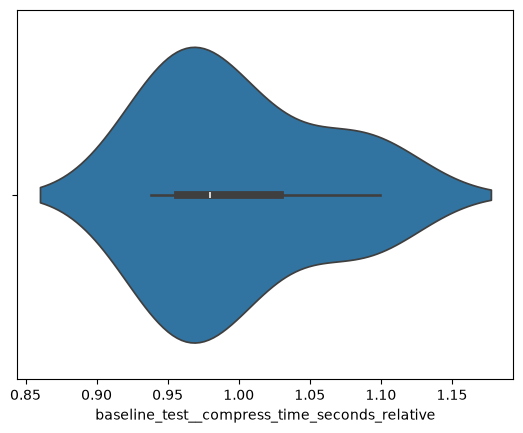

In [35]:
# Baseline variability
sns.violinplot(df.to_pandas(), x="baseline_test__compress_time_seconds_relative")

<Axes: xlabel='compress_time_seconds', ylabel='compression_ratio'>

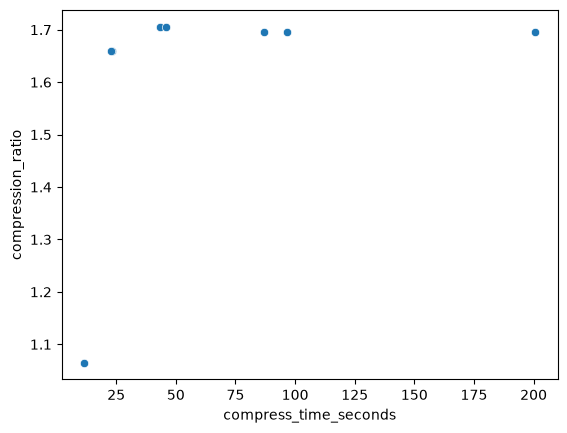

In [36]:
sns.scatterplot(df.to_pandas(), x="compress_time_seconds", y="compression_ratio")

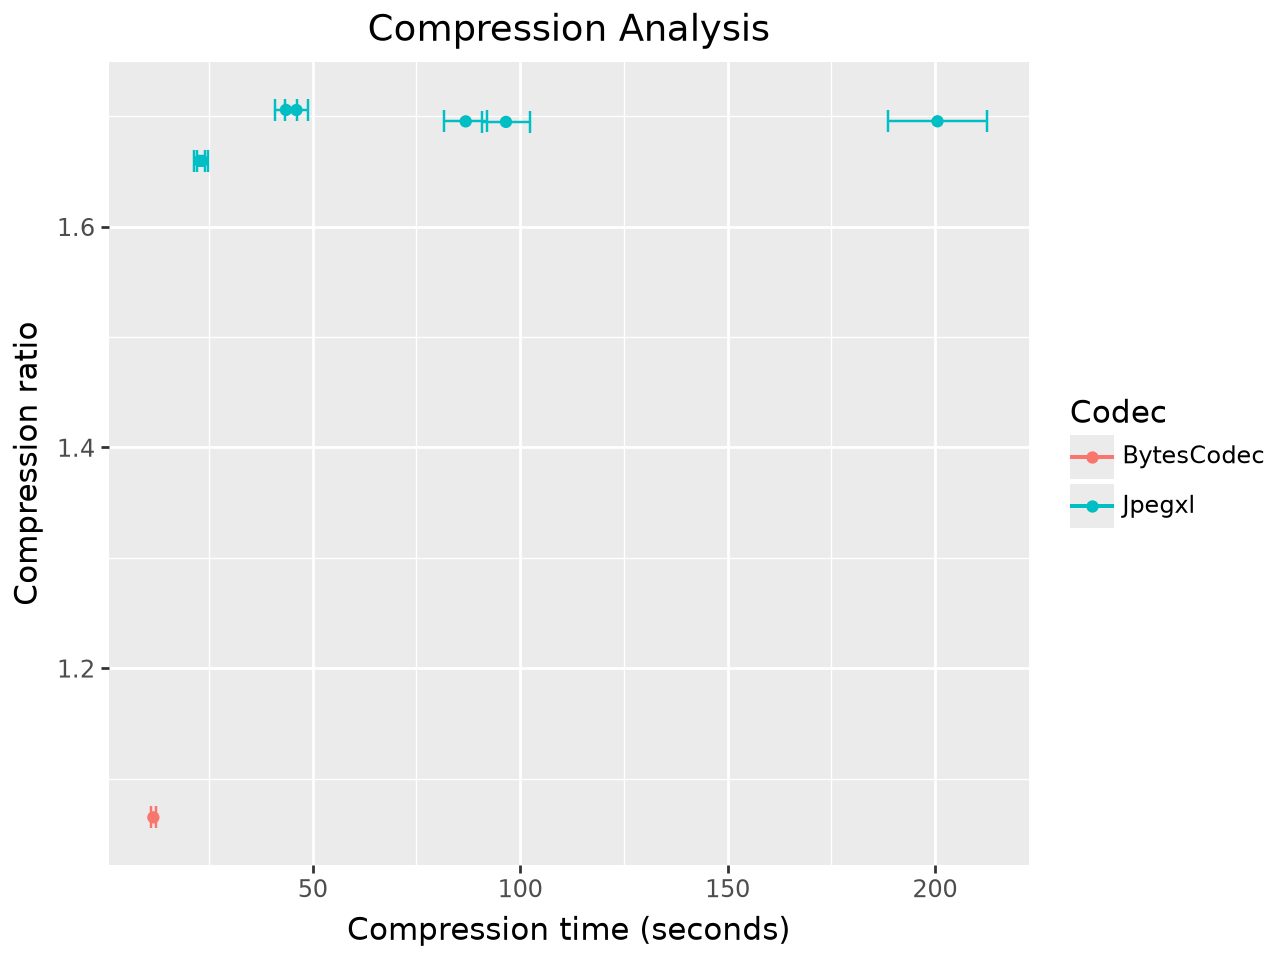

In [71]:
(
    p9.ggplot(df)
    + p9.aes(
        "compress_time_seconds", "compression_ratio", color="config__serializer[0]"
    )
    + p9.geom_point()
    + p9.aes(
        xmin="compress_time_seconds_lower_ci",
        xmax="compress_time_seconds_upper_ci",
    )
    + p9.geom_errorbarh(height=0.02)
    + p9.labs(
        title="Compression Analysis",
        x="Compression time (seconds)",
        y="Compression ratio",
    )
    + p9.scale_color_discrete(name="Codec")
    # + p9.theme_xkcd()
)